In [1]:
import os
base = "../data/chest_xray"
for split in ["train", "val", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        print(split, cls, len(os.listdir(os.path.join(base, split, cls))))

train NORMAL 1341
train PNEUMONIA 3875
val NORMAL 8
val PNEUMONIA 8
test NORMAL 234
test PNEUMONIA 390


Total NORMAL: 1583 | Total PNEUMONIA: 4273


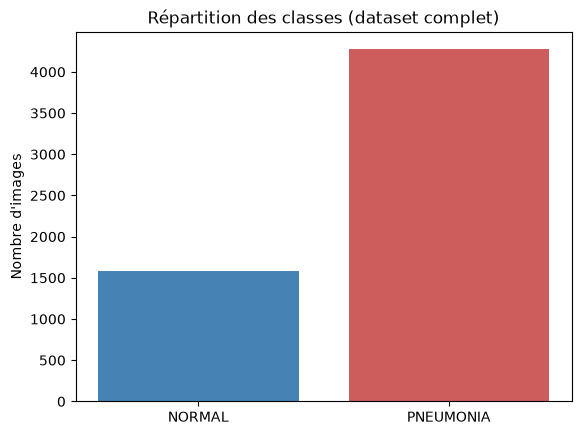

In [2]:
import os
import matplotlib.pyplot as plt

base = "../data/chest_xray"
counts = {}
for split in ["train", "val", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        counts[(split, cls)] = len(os.listdir(os.path.join(base, split, cls)))

total_normal = sum(v for (s, c), v in counts.items() if c == "NORMAL")
total_pneu = sum(v for (s, c), v in counts.items() if c == "PNEUMONIA")
print("Total NORMAL:", total_normal, "| Total PNEUMONIA:", total_pneu)

plt.bar(["NORMAL", "PNEUMONIA"], [total_normal, total_pneu], color=["steelblue", "indianred"])
plt.title("Répartition des classes (dataset complet)")
plt.ylabel("Nombre d'images")
plt.show()

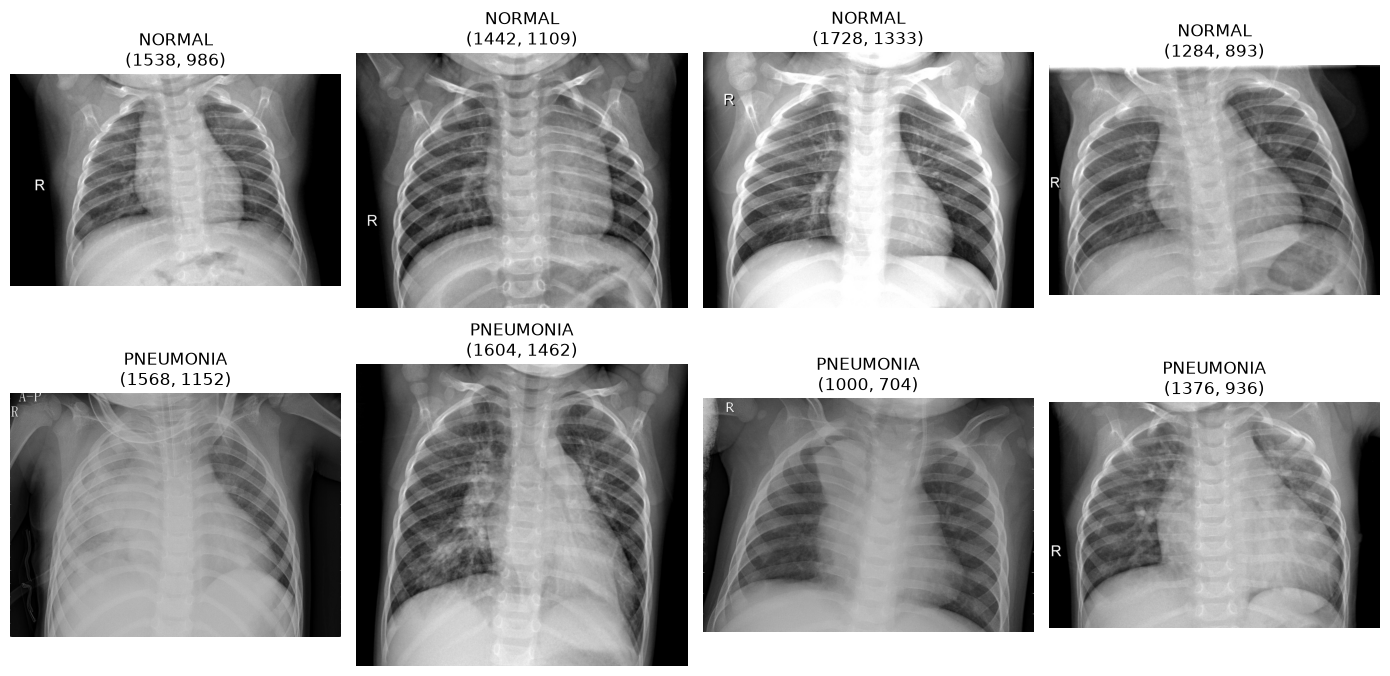

In [3]:
import random
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, cls in enumerate(["NORMAL", "PNEUMONIA"]):
    folder = os.path.join(base, "train", cls)
    for col, fname in enumerate(random.sample(os.listdir(folder), 4)):
        img = Image.open(os.path.join(folder, fname))
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(f"{cls}\n{img.size}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

rows = []
for split in ["train", "val", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(base, split, cls)
        for f in os.listdir(folder):
            rows.append({"path": os.path.join(folder, f), "label": cls})

df = pd.DataFrame(rows)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, len(d), d["label"].value_counts().to_dict())

os.makedirs("../data", exist_ok=True)
train_df.to_csv("../data/train.csv", index=False)
val_df.to_csv("../data/val.csv", index=False)
test_df.to_csv("../data/test.csv", index=False)

train 4099 {'PNEUMONIA': 2991, 'NORMAL': 1108}
val 878 {'PNEUMONIA': 641, 'NORMAL': 237}
test 879 {'PNEUMONIA': 641, 'NORMAL': 238}
